# Unique Models: EBM and CatBoost on Stylistic Features

The proposal pairs two less common models on one engineered feature set: an **Explainable Boosting Machine (EBM)**, which is interpretable by construction, and **CatBoost**, a black-box gradient-boosting model used as the stronger accuracy anchor. Both are trained on the same dense features: 14 stylistic features computed from the title and body, plus the top-30 TF-IDF terms used in every other notebook.

| Section | Question |
|---|---|
| 3 | Which stylistic features are engineered, and which are left out because they are scraping artefacts? |
| 6 | How do the two models perform on the shared test set? |
| 7 | What does the EBM show natively (one shape function per feature)? |
| 8 | Does PFI confirm the EBM's native importance ranking? |
| 9–10 | Does the black-box CatBoost (explained with TreeSHAP) rely on the same drivers as the glass-box EBM? |
| 11 | Do post-hoc methods recover what the EBM shows natively (LIME vs exact EBM contributions; CatBoost ALE vs EBM shape functions)? |

Same cleaned data, preprocessing, train/test split, top-30 terms and seed (`RANDOM_STATE = 42`) as the other model notebooks.

## 1. Setup

In [1]:
import os, sys, re, time, warnings
if not os.path.exists("preprocessing.py"):
    os.chdir(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (recall_score, precision_score, accuracy_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from interpret.glassbox import ExplainableBoostingClassifier
from catboost import CatBoostClassifier, Pool
from lime.lime_tabular import LimeTabularExplainer

from preprocessing import preprocess_text, get_split_tfidf, select_top_k_terms, RANDOM_STATE

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

## 2. Load the Cleaned Data and the Shared Split

In [2]:
df = pd.read_csv("Dataset/fake_news_dataset_cleaned.csv.gz")
df["full_text"] = df["title"] + " " + df["text"]
df["processed_text"] = df["full_text"].apply(preprocess_text)

X_train_tfidf, X_test_tfidf, y_train, y_test, tfidf = get_split_tfidf(df)
feature_names = tfidf.get_feature_names_out()
top_idx, top_terms, _ = select_top_k_terms(X_train_tfidf, y_train, feature_names, k=30, method="chi2")
print("Train:", X_train_tfidf.shape, "| Test:", X_test_tfidf.shape)
print("Top-30 terms:", ", ".join(top_terms))

Train: (30906, 5000) | Test: (7727, 5000)
Top-30 terms: video, said, image, via, featured, com, hillary, watch, pic, minister, gop, like, korea, china, black, http, trump, getty, know, twitter, eu, racist, reuters, north, america, even, fact, thing, woman, actually


## 3. Engineered Stylistic Features

The shared TF-IDF pipeline lowercases the text and removes punctuation, so the common models never see how an article is written beyond its words. These 14 features put that back, computed on the raw title and body of the cleaned dataset:

| Feature | Definition |
|---|---|
| `title_words`, `text_words` | number of words in the title and the body |
| `avg_word_length` | mean letters per word in the body |
| `words_per_sentence` | body words per sentence (sentences split on . ! ?) |
| `title_caps_share`, `text_caps_share` | share of words written in capitals (e.g. "BREAKING") |
| `title_exclamations`, `title_questions` | number of ! and ? in the title |
| `exclamations_per_100w`, `questions_per_100w` | ! and ? in the body per 100 words |
| `first_person_per_100w` | I, me, my, mine, we, us, our, ours per 100 words |
| `second_person_per_100w` | you, your, yours per 100 words |
| `type_token_ratio` | distinct words / words, over the first 300 words (so length does not drive it) |
| `digit_share` | share of body characters that are digits |

**Left out on purpose.** The EDA found that ISOT's fake bodies lost their quotation marks and apostrophes when they were scraped ("couldn t", next cell). A feature counting quotation marks would therefore measure the scraping, not the writing, so none is used, and one-letter tokens (the "t" of "couldn t") are dropped before counting words. URLs, Twitter handles and photo credits are not engineered either: they already enter through the top-30 terms (via, image, getty, http, pic, twitter).

In [3]:
pd.DataFrame({
    "body contains a double quote": df["text"].str.contains('["“”]', regex=True),
    "body contains an apostrophe (' or ’)": df["text"].str.contains("['’]", regex=True),
}).groupby(df["label"]).mean().round(3)

,body contains a double quote,body contains an apostrophe (' or ’)
label,,
fake,0.052,0.098
real,0.468,0.482


Double quotation marks appear in 47% of real bodies but only 5% of fake ones, and apostrophes in 48% against 10%. Fake sites do quote people; their quotation marks were lost when ISOT was scraped. A quotation feature would let the models detect the scraping, so it is left out.

In [4]:
WORD = re.compile(r"[A-Za-z]+")
FIRST = {"i", "me", "my", "mine", "we", "us", "our", "ours"}
SECOND = {"you", "your", "yours"}

def words(s):
    # letters only; one-letter tokens are dropped because fake bodies lost their apostrophes ("couldn t")
    return [w for w in WORD.findall(s) if len(w) > 1]

def style_features(title, text):
    tw, bw = words(title), words(text)
    all_low = [w.lower() for w in WORD.findall(text)]     # keeps "I" for the pronoun counts
    nb, nt = max(len(bw), 1), max(len(tw), 1)
    sentences = [x for x in re.split(r"[.!?]+", text) if WORD.search(x)]
    first300 = [w.lower() for w in bw[:300]]
    return {
        "title_words": len(tw),
        "text_words": len(bw),
        "avg_word_length": float(np.mean([len(w) for w in bw])) if bw else 0.0,
        "words_per_sentence": len(bw) / max(len(sentences), 1),
        "title_caps_share": sum(w.isupper() for w in tw) / nt,
        "text_caps_share": sum(w.isupper() for w in bw) / nb,
        "title_exclamations": title.count("!"),
        "title_questions": title.count("?"),
        "exclamations_per_100w": 100 * text.count("!") / nb,
        "questions_per_100w": 100 * text.count("?") / nb,
        "first_person_per_100w": 100 * sum(w in FIRST for w in all_low) / nb,
        "second_person_per_100w": 100 * sum(w in SECOND for w in all_low) / nb,
        "type_token_ratio": len(set(first300)) / max(len(first300), 1),
        "digit_share": sum(ch.isdigit() for ch in text) / max(len(text), 1),
    }

style = pd.DataFrame([style_features(a, b) for a, b in zip(df["title"], df["text"])], index=df.index)
STYLE = list(style.columns)
summary = style.groupby(df["label"]).agg(["median", "mean"]).T.unstack()
display(summary.round(3))

label                      fake              real         
                         median     mean   median     mean
title_words              14.000   14.264   10.000    9.718
text_words              365.000  412.336  340.000  365.273
avg_word_length           4.856    4.867    5.151    5.160
words_per_sentence       17.429   17.719   18.421   18.858
title_caps_share          0.143    0.190    0.000    0.018
text_caps_share           0.008    0.019    0.003    0.007
title_exclamations        0.000    0.122    0.000    0.001
title_questions           0.000    0.059    0.000    0.007
exclamations_per_100w     0.000    0.389    0.000    0.023
questions_per_100w        0.000    0.376    0.000    0.020
first_person_per_100w     1.040    1.415    0.346    0.699
second_person_per_100w    0.269    0.594    0.000    0.074
type_token_ratio          0.600    0.620    0.613    0.635
digit_share               0.004    0.007    0.004    0.006

The stylistic differences are the ones the proposal expected. Fake articles have longer titles (median 14 words against 10), partly in capitals (median 14% of title words against none), use first- and second-person words about three times as often (median 1.04 against 0.35 and 0.27 against 0 per 100 words) and use far more exclamation and question marks (mean 0.39 against 0.02 and 0.38 against 0.02 per 100 words). Reuters articles use longer words (5.15 against 4.86 letters) and slightly longer sentences (18.4 against 17.4 words). Like every cue in ISOT, these describe the house style of Reuters against these particular sites as much as fake news in general.

## 4. Feature Set and Correlation Check

Each article gets its 14 stylistic features and the TF-IDF weights of the top-30 terms (prefixed `tfidf_`), 44 dense features in all. The proposal asks for a correlation check over this set before reading any explanation, because correlated features share credit.

Train: (30906, 44) | Test: (7727, 44)


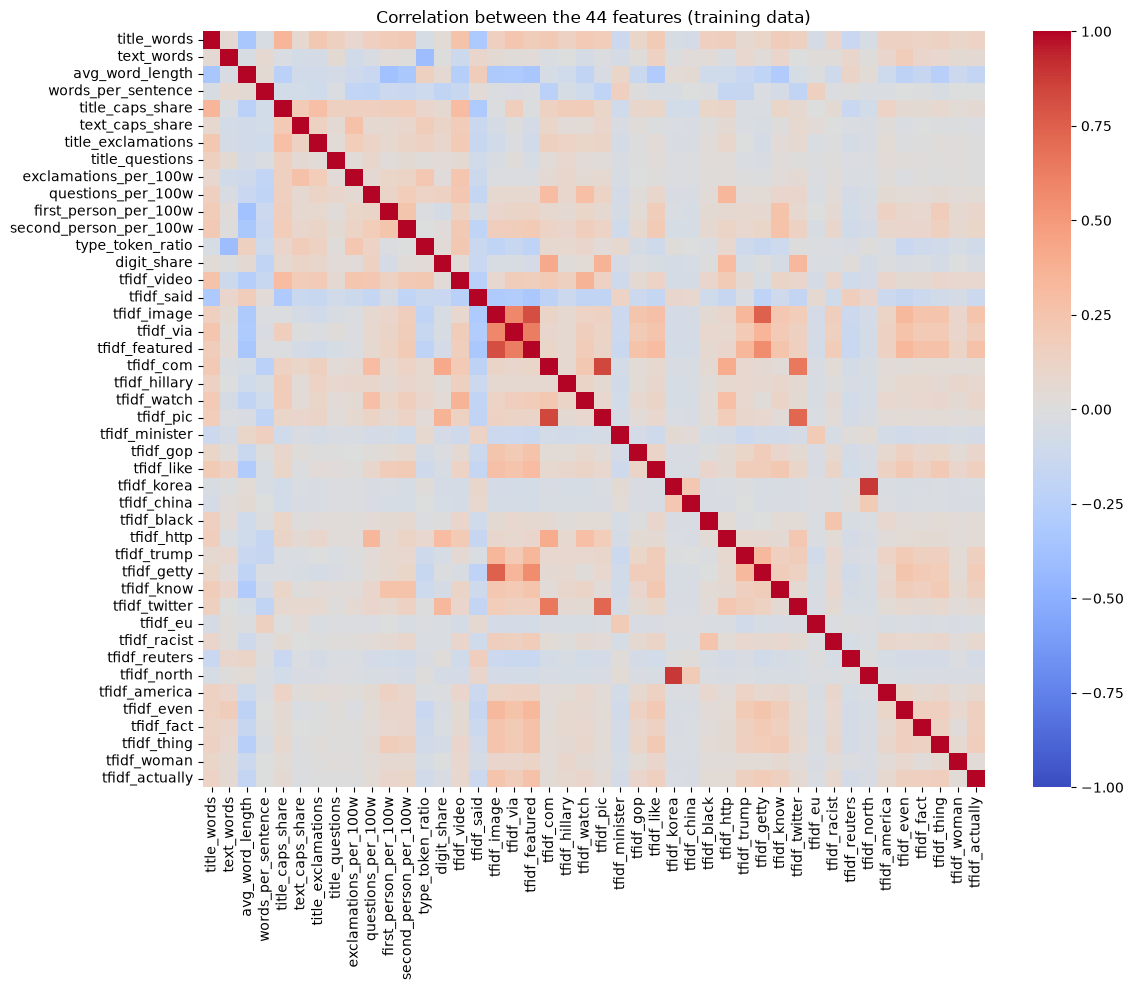

Pairs with |r| > 0.5:
tfidf_korea     tfidf_north       0.89
tfidf_com       tfidf_pic         0.84
tfidf_image     tfidf_featured    0.81
                tfidf_getty       0.74
tfidf_pic       tfidf_twitter     0.72
tfidf_com       tfidf_twitter     0.65
tfidf_via       tfidf_featured    0.63
tfidf_image     tfidf_via         0.58
tfidf_featured  tfidf_getty       0.56
dtype: float64
Largest |r| involving a stylistic feature: 0.42


In [5]:
TERMS = [f"tfidf_{t}" for t in top_terms]
def build(X_tfidf, index):
    terms = pd.DataFrame(X_tfidf[:, top_idx].toarray(), columns=TERMS, index=index)
    return pd.concat([style.loc[index], terms], axis=1)

X_train = build(X_train_tfidf, y_train.index)
X_test = build(X_test_tfidf, y_test.index)
FEATURES = list(X_train.columns)
print("Train:", X_train.shape, "| Test:", X_test.shape)

corr = X_train.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.title("Correlation between the 44 features (training data)")
plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high = pairs[pairs.abs() > 0.5].sort_values(key=abs, ascending=False)
print("Pairs with |r| > 0.5:"); print(high.round(2))
print("Largest |r| involving a stylistic feature:",
      pairs[[a in STYLE or b in STYLE for a, b in pairs.index]].abs().max().round(2))

The nine highly correlated pairs are the same term groups as in the other notebooks (photo credit, tweet links, North Korea). No stylistic feature correlates with any other feature above |r| = 0.42, so the credit each one receives is not split with a near-copy.

## 5. Train EBM and CatBoost

- **EBM** (`interpret`): one shape function per feature and no pairwise interactions (`interactions=0`), so every prediction is exactly the intercept plus one additive score per feature, which is what makes it a glass box.
- **CatBoost**: 500 trees of depth 6 with ordered boosting (`boosting_type="Ordered"`), as in the proposal, to reduce overfitting.

In [6]:
t = time.time()
ebm = ExplainableBoostingClassifier(interactions=0, random_state=RANDOM_STATE, n_jobs=-1)
ebm.fit(X_train, y_train)
print(f"EBM trained in {time.time() - t:.0f} s: {len(ebm.term_names_)} shape functions, "
      f"{sum(len(s) for s in ebm.term_scores_)} score bins in total")

t = time.time()
cat = CatBoostClassifier(iterations=500, depth=6, learning_rate=0.1, boosting_type="Ordered",
                         random_seed=RANDOM_STATE, verbose=0, thread_count=-1,
                         allow_writing_files=False)
cat.fit(X_train, y_train)
print(f"CatBoost trained in {time.time() - t:.0f} s: {cat.tree_count_} trees of depth 6 "
      f"({cat.tree_count_ * 2**6:,} leaves) over {len(FEATURES)} features")

EBM trained in 35 s: 44 shape functions, 40904 score bins in total


CatBoost trained in 30 s: 500 trees of depth 6 (32,000 leaves) over 44 features


## 6. Performance on the Shared Test Set

The logistic regression baseline is retrained here exactly as in its own notebook (TF-IDF, same split), so all three rows use the same 7,727 test articles.

,fake_recall,precision,accuracy,roc_auc,missed_fakes,false_alarms
model,,,,,,
"Logistic regression (TF-IDF, baseline)",0.9690,0.9872,0.9803,0.9978,108,44
EBM (14 stylistic + 30 terms),0.9862,0.9945,0.9913,0.9997,48,19
CatBoost (14 stylistic + 30 terms),0.9885,0.9957,0.9929,0.9997,40,15


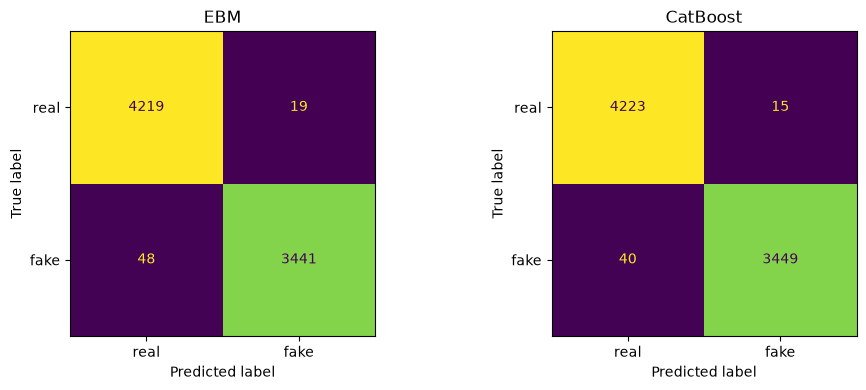

In [7]:
lr = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000).fit(X_train_tfidf, y_train)

def scores(name, y_pred, p_fake):
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return {"model": name, "fake_recall": recall_score(y_test, y_pred), "precision": precision_score(y_test, y_pred),
            "accuracy": accuracy_score(y_test, y_pred), "roc_auc": roc_auc_score(y_test, p_fake),
            "missed_fakes": fn, "false_alarms": fp}

perf = pd.DataFrame([
    scores("Logistic regression (TF-IDF, baseline)", lr.predict(X_test_tfidf), lr.predict_proba(X_test_tfidf)[:, 1]),
    scores("EBM (14 stylistic + 30 terms)", ebm.predict(X_test), ebm.predict_proba(X_test)[:, 1]),
    scores("CatBoost (14 stylistic + 30 terms)", cat.predict(X_test), cat.predict_proba(X_test)[:, 1]),
]).set_index("model")
display(perf.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, [("EBM", ebm), ("CatBoost", cat)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)), display_labels=["real", "fake"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

On the same 7,727 test articles, both models catch more fakes than any TF-IDF model: Fake-class recall 0.986 for the EBM and 0.989 for CatBoost, against 0.969 for the baseline and 0.975 for the SVM (`SVM.ipynb`), with fewer false alarms (19 and 15, against 44 and 39).

- **The black box buys almost nothing here.** The glass-box EBM is within 0.2 recall points of CatBoost (48 against 40 missed fakes), on the same features.
- **The gain comes with the features, not the model.** Both models share the 14 stylistic features, which put back capitals, punctuation and length, information the shared TF-IDF preprocessing removes.
- **The explained model stays the SVM.** The proposal's rule picks the explained model among the common TF-IDF models, and every faithfulness and stability test in `xai_evaluation.ipynb` is run on it. A reviewer who wants a screen that explains itself could use this EBM instead: it is more accurate than the SVM and can be read in full.

## 7. EBM: The Native Explanation

The EBM's importance of a feature is the mean absolute score it adds to the log-odds over the training articles. Its shape function shows that score at every value of the feature; no post-hoc method is involved.

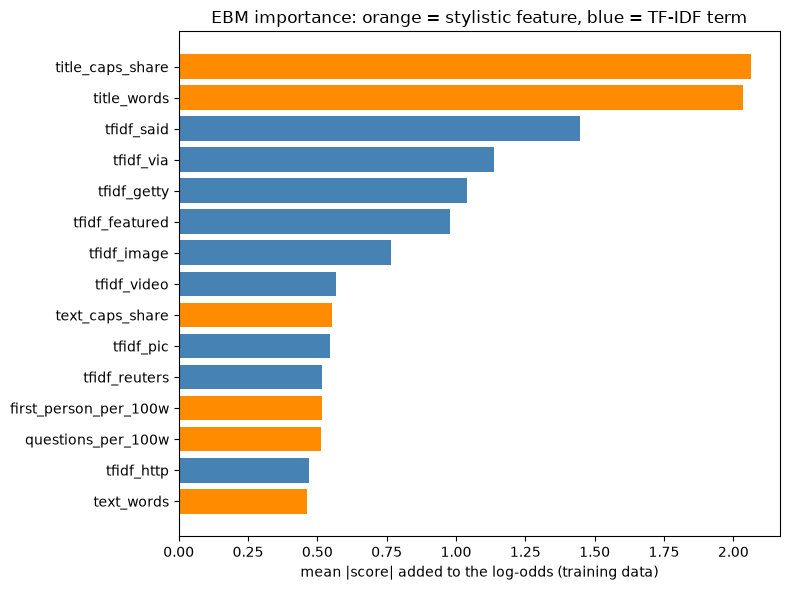

Share of EBM importance on the 14 stylistic features: 41.4%


,EBM importance
title_caps_share,2.065
title_words,2.036
tfidf_said,1.447
tfidf_via,1.138
tfidf_getty,1.040
tfidf_featured,0.979
tfidf_image,0.764
tfidf_video,0.566
text_caps_share,0.553
tfidf_pic,0.547


In [8]:
ebm_imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values(ascending=False)
style_share_ebm = ebm_imp[STYLE].sum() / ebm_imp.sum()

top = ebm_imp.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["darkorange" if f in STYLE else "steelblue" for f in top.index])
plt.xlabel("mean |score| added to the log-odds (training data)")
plt.title("EBM importance: orange = stylistic feature, blue = TF-IDF term")
plt.tight_layout(); plt.show()
print(f"Share of EBM importance on the 14 stylistic features: {style_share_ebm:.1%}")
display(ebm_imp.head(15).round(3).to_frame("EBM importance"))

Stylistic features carry 41% of the EBM's importance. The two most important features both describe the title, its share of capitalised words (2.07) and its length (2.04). They rank ahead of the strongest word, "said" (1.45), and the photo-credit words (via 1.14, getty 1.04, featured 0.98).

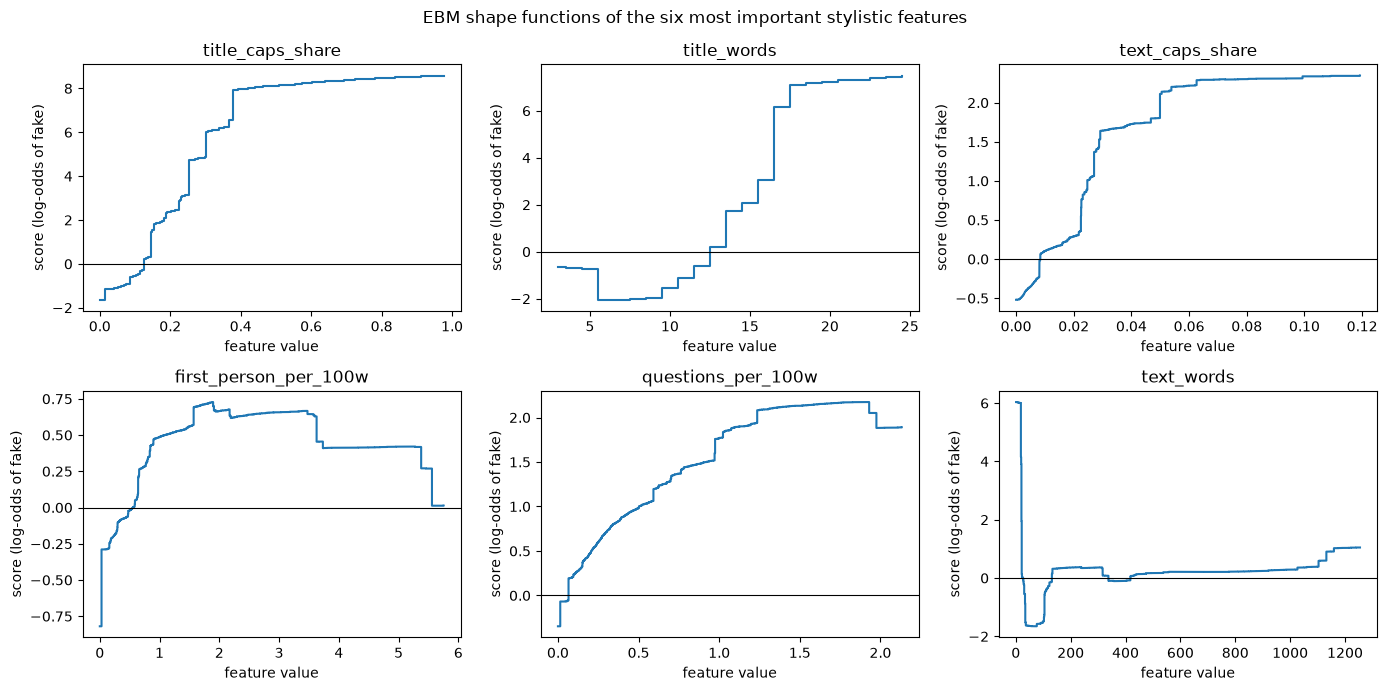

In [9]:
ebm_global = ebm.explain_global()
top_style = [f for f in ebm_imp.index if f in STYLE][:6]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), top_style):
    d = ebm_global.data(ebm.term_names_.index(f))
    edges, sc = np.asarray(d["names"], dtype=float), np.asarray(d["scores"], dtype=float)
    hi = np.quantile(X_train[f], 0.99)                       # show the range that holds 99% of articles
    keep = edges[:-1] <= hi
    ax.step(edges[:-1][keep], sc[keep], where="post")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f); ax.set_xlabel("feature value"); ax.set_ylabel("score (log-odds of fake)")
plt.suptitle("EBM shape functions of the six most important stylistic features")
plt.tight_layout(); plt.show()

The shape functions show how each feature acts:

- **Capitals in the title.** Below about 13% capitalised words the score favours real (−1.6 log-odds for none); from 15% it favours fake, reaching +8 once 40% of the title is in capitals. All 403 test articles with such titles are fake.
- **Title length.** Titles of 6 to 12 words push toward real (−2.0 to −0.6); from 14 words the score rises steeply, to +6 to +7 from 17 words. 716 test titles are that long, 99.7% of them fake.
- **Body.** Capitals (+1.6 to +2.3 above 3% of words), question marks (+1.8 at one per 100 words) and first-person words (+0.5 to +0.7 between 1 and 3 per 100 words) push steadily toward fake.
- **Very short bodies.** Bodies of 10 words or fewer score +6 (+3.9 at 20 words). Bodies under 20 words are rare (71 test articles), and 98.6% of them are fake.

## 8. Does PFI Confirm the EBM's Ranking?

The proposal keeps PFI for the EBM to check its native ranking against actual performance loss. Correlated terms (Section 4) are shuffled together as one unit, as in the other notebooks; each stylistic feature is shuffled on its own.

In [10]:
groups = []
for a, b in high.index:
    linked = [g for g in groups if a in g or b in g]
    merged = {a, b}.union(*linked)
    groups = [g for g in groups if g not in linked] + [merged]
units = []
for f in FEATURES:
    g = next((g for g in groups if f in g), {f})
    u = [x for x in FEATURES if x in g]
    if u not in units:
        units.append(u)

def pfi_recall(model, X, y, units, n_repeats=5, seed=RANDOM_STATE):
    rng = np.random.RandomState(seed)
    base = recall_score(y, model.predict(X))
    rows = []
    for u in units:
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[u] = X[u].values[rng.permutation(len(X))]
            drops.append(base - recall_score(y, model.predict(Xp)))
        rows.append({"unit": ", ".join(u), "recall_drop": np.mean(drops), "std": np.std(drops),
                     "ebm_importance": ebm_imp[u].sum()})
    return pd.DataFrame(rows).sort_values("recall_drop", ascending=False)

pfi = pfi_recall(ebm, X_test, y_test, units)
rho_pfi = spearmanr(pfi["recall_drop"], pfi["ebm_importance"]).correlation
print(f"{len(FEATURES)} features -> {len(units)} PFI units; Spearman(PFI drop, EBM importance) = {rho_pfi:.2f}")
display(pfi.head(10).round(4))

44 features -> 38 PFI units; Spearman(PFI drop, EBM importance) = 0.51


,unit,recall_drop,std,ebm_importance
16,"tfidf_image, tfidf_via, tfidf_featured, tfidf_...",0.0499,0.0019,3.9214
4,title_caps_share,0.0225,0.0016,2.0651
0,title_words,0.0079,0.0010,2.0361
15,tfidf_said,0.0078,0.0009,1.4470
5,text_caps_share,0.0034,0.0008,0.5534
31,tfidf_reuters,0.0015,0.0010,0.5165
9,questions_per_100w,0.0013,0.0003,0.5136
8,exclamations_per_100w,0.0011,0.0005,0.2966
6,title_exclamations,0.0011,0.0003,0.2561
29,tfidf_eu,0.0010,0.0001,0.1858


PFI confirms the EBM's top of the ranking. The four units that cost most Fake-class recall when shuffled are, in the same order, the four with the largest native importance: the photo-credit group (0.050), title capitals (0.023), title length (0.008) and "said" (0.008). Below them most drops are near zero, so the rank correlation over all 38 units is only moderate (ρ = 0.51).

## 9. CatBoost: TreeSHAP

CatBoost computes exact TreeSHAP values itself (`type="ShapValues"`). The check below confirms that each article's SHAP values add up to the model's raw score.

Additivity: max |sum(SHAP) + expected - raw score| = 3.73e-14


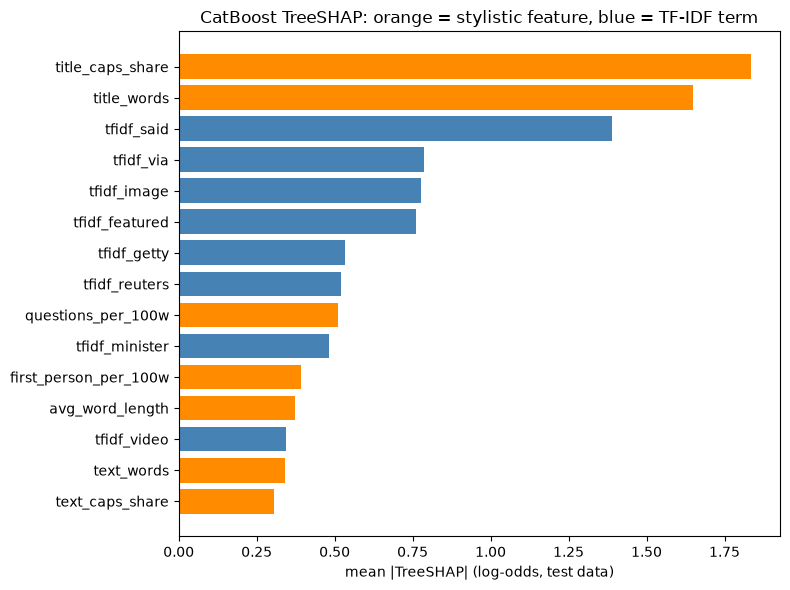

Share of CatBoost |SHAP| on the 14 stylistic features: 45.5%


In [11]:
sv = cat.get_feature_importance(Pool(X_test, y_test), type="ShapValues")      # last column = expected value
shap_vals, expected = sv[:, :-1], sv[0, -1]
raw = cat.predict(X_test, prediction_type="RawFormulaVal")
print(f"Additivity: max |sum(SHAP) + expected - raw score| = {np.abs(shap_vals.sum(1) + expected - raw).max():.2e}")

shap_imp = pd.Series(np.abs(shap_vals).mean(0), index=FEATURES).sort_values(ascending=False)
style_share_cat = shap_imp[STYLE].sum() / shap_imp.sum()
top = shap_imp.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["darkorange" if f in STYLE else "steelblue" for f in top.index])
plt.xlabel("mean |TreeSHAP| (log-odds, test data)")
plt.title("CatBoost TreeSHAP: orange = stylistic feature, blue = TF-IDF term")
plt.tight_layout(); plt.show()
print(f"Share of CatBoost |SHAP| on the 14 stylistic features: {style_share_cat:.1%}")

The TreeSHAP values add up to CatBoost's raw score (error 4 × 10⁻¹⁴). Stylistic features carry 46% of CatBoost's mean |SHAP|, and the same two title features lead: capitals (1.84) and length (1.65), followed by "said" (1.39) and the photo-credit words.

## 10. Glass Box vs Black Box: Do They Rely on the Same Drivers?

Spearman rank correlation of the 44 importances: 0.90
Top-10 overlap: 7 of 10 (tfidf_featured, tfidf_getty, tfidf_image, tfidf_said, tfidf_via, title_caps_share, title_words)
Only in EBM top 10: ['text_caps_share', 'tfidf_pic', 'tfidf_video'] | only in CatBoost top 10: ['questions_per_100w', 'tfidf_minister', 'tfidf_reuters']
Stylistic share of importance: EBM 41.4%, CatBoost 45.5%


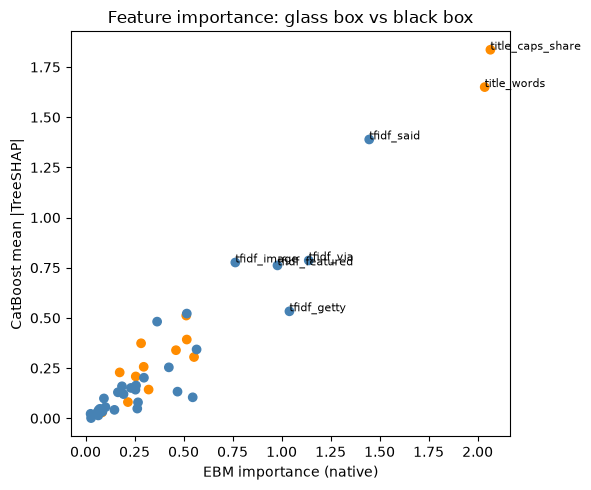

In [12]:
both = pd.DataFrame({"ebm": ebm_imp, "catboost_shap": shap_imp}).loc[FEATURES]
rho_models = spearmanr(both["ebm"], both["catboost_shap"]).correlation
top10_e, top10_c = set(ebm_imp.index[:10]), set(shap_imp.index[:10])
print(f"Spearman rank correlation of the 44 importances: {rho_models:.2f}")
print(f"Top-10 overlap: {len(top10_e & top10_c)} of 10 ({', '.join(sorted(top10_e & top10_c))})")
print(f"Only in EBM top 10: {sorted(top10_e - top10_c)} | only in CatBoost top 10: {sorted(top10_c - top10_e)}")
print(f"Stylistic share of importance: EBM {style_share_ebm:.1%}, CatBoost {style_share_cat:.1%}")

plt.figure(figsize=(6, 5))
plt.scatter(both["ebm"], both["catboost_shap"], c=["darkorange" if f in STYLE else "steelblue" for f in both.index])
for f in set(ebm_imp.index[:6]) | set(shap_imp.index[:6]):
    plt.annotate(f, (both.loc[f, "ebm"], both.loc[f, "catboost_shap"]), fontsize=8)
plt.xlabel("EBM importance (native)"); plt.ylabel("CatBoost mean |TreeSHAP|")
plt.title("Feature importance: glass box vs black box")
plt.tight_layout(); plt.show()

The glass box and the black box rely on the same drivers:

- **Rankings:** the 44 importances correlate at Spearman ρ = 0.90.
- **Top features:** seven of the two top-10 lists coincide, namely both title features, "said" and four photo-credit words.
- **Stylistic share:** stylistic features take 41% (EBM) and 46% (CatBoost) of the importance.
- **Differences:** CatBoost leans a little more on question marks, "minister" and "reuters"; the EBM on body capitals, "pic" and "video".

This is the convergence the proposal set out to test. Two models built in different ways, one explained natively and one by TreeSHAP, both put the title's capitals and length first.

## 11. Do Post-hoc Methods Recover What the EBM Shows Natively?

Because the EBM is additive, its exact per-article explanation is known: the score each feature adds to the log-odds. That makes it a white-box test case for post-hoc methods, as the logistic regression and decision tree are in `xai_evaluation.ipynb`.

**(a) LIME vs exact EBM contributions.** For 50 random test articles, LIME (tabular, 1,000 samples, all 44 features) explains the EBM. We compare LIME's weights with the EBM's exact contributions: Spearman ρ over the 44 features, the share of LIME's top-5 features that are also in the exact top 5, and the sign agreement of LIME's top 5.

In [13]:
contrib = ebm.eval_terms(X_test.values)                                  # exact per-feature scores (log-odds)
logit = ebm.decision_function(X_test)                                     # the EBM's log-odds of fake
print(f"EBM additivity: max |intercept + sum(scores) - log-odds| = {np.abs(contrib.sum(1) + ebm.intercept_ - logit).max():.1e}")

lime_tab = LimeTabularExplainer(X_train.values, feature_names=FEATURES, class_names=["real", "fake"],
                                discretize_continuous=True, random_state=RANDOM_STATE)
sample = np.random.RandomState(RANDOM_STATE).choice(len(X_test), 50, replace=False)
rows = []
for i in sample:
    exp = lime_tab.explain_instance(X_test.values[i], ebm.predict_proba, num_features=len(FEATURES),
                                    num_samples=1000, labels=(1,))
    w = np.zeros(len(FEATURES))
    for j, v in exp.as_map()[1]:
        w[j] = v
    exact = contrib[i]
    top_l, top_e = np.argsort(-np.abs(w))[:5], np.argsort(-np.abs(exact))[:5]
    rows.append({"spearman": spearmanr(w, exact).correlation,
                 "precision_at_5": len(set(top_l) & set(top_e)) / 5,
                 "sign_agreement_top5": np.mean(np.sign(w[top_l]) == np.sign(exact[top_l])),
                 "same_top1": float(top_l[0] == top_e[0])})
lime_vs_ebm = pd.DataFrame(rows)
display(lime_vs_ebm.agg(["mean", "min", "median"]).round(3))

EBM additivity: max |intercept + sum(scores) - log-odds| = 2.1e-14


,spearman,precision_at_5,sign_agreement_top5,same_top1
mean,0.815,0.348,1.0,0.24
min,0.590,0.000,1.0,0.00
median,0.825,0.400,1.0,0.00


**LIME gets the direction right but not the ranking.** Across 50 articles, every feature in LIME's top 5 has the correct sign (100%), and LIME's weights correlate with the exact EBM contributions at mean ρ = 0.82 (lowest 0.59). But only 35% of LIME's top 5 are in the exact top 5, and LIME's top feature matches the EBM's in only 24% of articles.

Tabular LIME scores whether a feature falls into a quartile bin, not how far it is from average. A fully capitalised title and a slightly capitalised one can therefore get similar weights. On text, LIME recovered 84% of the logistic regression's top-5 words (`xai_evaluation.ipynb`), which suggests that the shortfall here comes from the tabular discretisation. A reviewer shown tabular LIME for this model should trust its signs, not its order.

**(b) CatBoost ALE vs EBM shape functions.** ALE is the post-hoc method used for the black-box models in this project. If CatBoost and the EBM learned the same relationship for a feature, CatBoost's ALE curve (in log-odds) should follow the EBM's native shape function. Both curves are centred and compared on the same quantile grid, using Pearson's r between them.

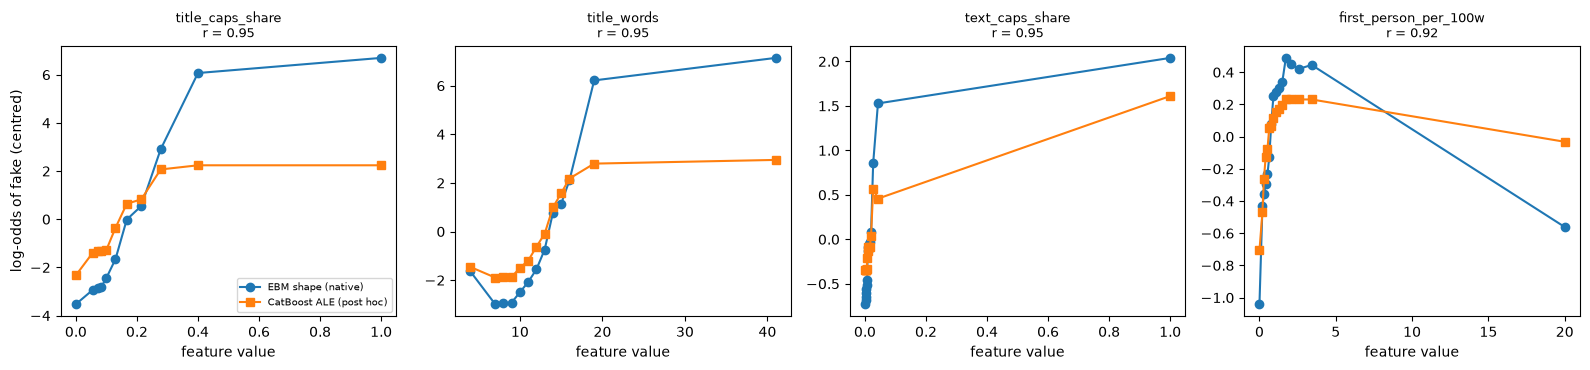

,feature,grid_points,pearson_r
0,title_caps_share,11,0.948
1,title_words,13,0.949
2,text_caps_share,15,0.948
3,first_person_per_100w,16,0.920


In [14]:
def ale_1d(predict, X, col, n_bins=20):
    x = X[:, col]
    edges = np.unique(np.quantile(x, np.linspace(0, 1, n_bins + 1)))
    if len(edges) < 2:
        return edges, np.zeros(len(edges))
    bin_idx = np.clip(np.searchsorted(edges, x, side="left"), 1, len(edges) - 1)
    effects, counts = np.zeros(len(edges) - 1), np.zeros(len(edges) - 1)
    for k in range(1, len(edges)):
        rows_k = X[bin_idx == k]
        if len(rows_k) == 0:
            continue
        lo, hi = rows_k.copy(), rows_k.copy()
        lo[:, col], hi[:, col] = edges[k - 1], edges[k]
        effects[k - 1] = (predict(hi) - predict(lo)).mean()
        counts[k - 1] = len(rows_k)
    ale = np.concatenate([[0.0], np.cumsum(effects)])
    mids = (ale[:-1] + ale[1:]) / 2
    return edges, ale - (mids * counts).sum() / counts.sum()

def ebm_shape_at(f, values):
    d = ebm_global.data(ebm.term_names_.index(f))
    edges, sc = np.asarray(d["names"], dtype=float), np.asarray(d["scores"], dtype=float)
    return sc[np.clip(np.searchsorted(edges, values, side="right") - 1, 0, len(sc) - 1)]

cat_logodds = lambda X: cat.predict(X, prediction_type="RawFormulaVal")
X_ale = X_test.values
ale_rows = []
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, f in zip(axes, top_style[:4]):
    edges, ale = ale_1d(cat_logodds, X_ale, FEATURES.index(f))
    shape = ebm_shape_at(f, edges)
    shape = shape - shape.mean(); ale_c = ale - ale.mean()
    r = np.corrcoef(shape, ale_c)[0, 1] if len(edges) > 2 else np.nan
    ale_rows.append({"feature": f, "grid_points": len(edges), "pearson_r": r})
    ax.plot(edges, shape, marker="o", label="EBM shape (native)")
    ax.plot(edges, ale_c, marker="s", label="CatBoost ALE (post hoc)")
    ax.set_title(f"{f}\nr = {r:.2f}", fontsize=9); ax.set_xlabel("feature value")
axes[0].set_ylabel("log-odds of fake (centred)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
display(pd.DataFrame(ale_rows).round(3))

**The post-hoc ALE curves of CatBoost follow the EBM's native shape functions closely.** For the four most important stylistic features the correlation is r = 0.92 to 0.95: the effects rise at the same thresholds and in the same direction. CatBoost's curves are flatter at the extremes; for fully capitalised titles, for example, they reach about +2 log-odds against about +7 for the EBM (both centred). The two models therefore agree on where each effect lies and which way it points, less on how large it is. The curves have only 11 to 16 grid points each, so r is indicative.

## 12. Summary

1. **Accuracy.** On 14 stylistic features plus the top-30 terms, the EBM (Fake recall 0.986) and CatBoost (0.989) outperform every TF-IDF model, including the SVM (0.975). The glass box is within 0.2 points of the black box, so the gain comes with the features (capitals, punctuation, length), not with model complexity.
2. **What drives them.** The title's share of capitals and its length are the two most important features for both models, ahead of "said" and the photo-credit words. Stylistic features carry 41% (EBM) and 46% (CatBoost) of the importance.
3. **Glass box vs black box.** EBM importances and CatBoost TreeSHAP agree (Spearman ρ = 0.90, 7 of the top 10 shared). CatBoost's post-hoc ALE curves follow the EBM's native shape functions (r = 0.92 to 0.95), though they are flatter at the extremes.
4. **PFI.** PFI confirms the EBM's four most important units in the same order; over all units the agreement is moderate (ρ = 0.51), because most units barely matter.
5. **LIME on a known model.** Tabular LIME recovers the sign of every top feature but only 35% of the EBM's exact top 5 (same top feature in 24% of articles). Its signs can be trusted on this model; its ranking cannot.

These stylistic cues are real differences between Reuters and the fake sites in ISOT: capitalised, long, conversational headlines. They are not evidence about whether an article is true. The quotation-mark feature was left out because ISOT's fake bodies lost their quotation marks in scraping.